# Understanding the TCGA SARC dataset

Before building a model, we need to understand our data. This notebook checks the samples, sarcoma labels, and gene-expression values.

**A sample** is a tumor specimen. **Gene expression** measures how actively a gene is used in that sample. **A label** tells us the sample's recorded sarcoma subtype.

## How to run it

1. Install `requirements-notebooks.txt` in your Python environment.
2. From the project folder, run `python -m src.data.prepare`.
3. Open this notebook, select that Python environment, restart the kernel, and run all cells from top to bottom.

Each section explains what we check, shows the code, and explains the result. The saved tables and charts come from a completed run. This notebook inspects the data without changing the files.


## 1 Set up Python

Find the project folder and load the settings and libraries we need. Show their versions so we know which software produced the results.


In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import re
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

# Find the project folder whether we start here or inside notebooks.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "configs/data.yaml").is_file():
    raise RuntimeError("Start from the repository root or its notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.audit import audit, load_config
config = load_config()

# Keep tables short and charts easy to read.
pd.set_option("display.max_columns", 8)
pd.set_option("display.max_colwidth", 65)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
display(pd.Series({"Python": sys.version.split()[0], "pandas": pd.__version__,
                   "NumPy": np.__version__, "Matplotlib": matplotlib.__version__},
                  name="Version").to_frame())


,Version
Python,3.12.14
pandas,3.0.1
NumPy,2.3.5
Matplotlib,3.11.2


The settings tell Python where the files are and which six subtypes to use. The version table helps us repeat this analysis in the same environment.


## 2 Check that the original files are unchanged

A **checksum** is a file's digital fingerprint. Compare each input file with the fingerprint saved in `DATA_SOURCES.md`. If they differ, stop and investigate.


In [2]:
# Use the same file checks as the preparation command.
audit_report = audit(config)
sources_document = (ROOT / "DATA_SOURCES.md").read_text(encoding="utf-8")
snapshot = dict(re.findall(r"`data/raw/([^`]+)`[^\n]*`([a-f0-9]{64})`", sources_document))
checksum_rows = []
for key in ("clinical_file", "expression_file"):
    path = config[key]
    actual = hashlib.sha256(path.read_bytes()).hexdigest()
    expected = snapshot.get(path.name)
    checksum_rows.append({"Input": path.name, "SHA-256": actual,
                          "Matches documented snapshot": actual == expected})
checksum_table = pd.DataFrame(checksum_rows)
display(checksum_table)
if not checksum_table["Matches documented snapshot"].all():
    raise ValueError("Input snapshot differs from DATA_SOURCES.md; review before proceeding.")
if not audit_report["matches_expected_class_counts"]:
    raise ValueError("The source cohort differs from the configured class counts.")


,Input,SHA-256,Matches documented snapshot
0,sarc_tcga_clinical_data.tsv,ef96a946f513bad5fac4fcdb8663586286db20b8cd04f5be5bc598c6e348d6b5,True
1,data_mrna_seq_v2_rsem.txt,e364fba8c62b01e40b17fc7cdf95e4e7487654f1aeeb81a0c055897aa8adceee,True


Both fingerprints match: we are using the expected files. The sample counts also match our project settings. This confirms the file versions, not the medical accuracy of their contents.


## 3 Load the data

Read the merged dataset and check that its expression values still match the original file. Separate the gene measurements from the sample IDs and subtype labels.


In [3]:
processed = config["processed_dir"]
if not (processed / "sarc_merged_six_subtypes.tsv").exists():
    raise FileNotFoundError("Run python -m src.data.prepare before this notebook.")
dataset = pd.read_csv(processed / "sarc_merged_six_subtypes.tsv", sep="\t")
gene_map = pd.read_csv(processed / "gene_feature_map.tsv", sep="\t",
                       dtype={"Hugo_Symbol": "string", "Entrez_Gene_Id": "string"})
clinical_columns = ["Sample ID", "Patient ID", "Cancer Type Detailed",
                    "Neoplasm Histologic Type Name", "Sample Type"]
full_clinical = pd.read_csv(processed / "sarc_merged_all.tsv", sep="\t",
                            usecols=clinical_columns)

# Put only gene measurements in X, leaving out IDs and labels.
gene_columns = [column for column in dataset if column.startswith("gene__")]
X = dataset[gene_columns].copy()
y = dataset["subtype"].copy()
assert gene_columns == gene_map["feature_column"].tolist()
assert dataset["Sample ID"].is_unique
assert dataset["Patient ID"].nunique() == len(dataset)
assert y.equals(dataset["Cancer Type Detailed"].map(config["target_subtypes"]))

# Check that merging preserved every original expression value.
raw_expression = pd.read_csv(config["expression_file"], sep="\t")
source_values = raw_expression[dataset["Sample ID"].tolist()].T.to_numpy()
np.testing.assert_allclose(X.to_numpy(), source_values, rtol=1e-14, atol=0, equal_nan=True)
assert len(X) == audit_report["target_samples"]
del raw_expression, source_values
display(pd.DataFrame({"Role": ["Sample identifier", "Validation group", "Original label",
                               "Model target", "Expression inputs"],
                      "Columns": ["Sample ID", "Patient ID", "Cancer Type Detailed",
                                  "subtype", f"{len(gene_columns):,} gene__ columns"]}))


,Role,Columns
0,Sample identifier,Sample ID
1,Validation group,Patient ID
2,Original label,Cancer Type Detailed
3,Model target,subtype
4,Expression inputs,"20,531 gene__ columns"


We have **254 samples and 20,531 gene measurements per sample**, with one sample per patient.

`X` holds the gene measurements the model will use. `y` holds the subtype it will try to predict. IDs and subtype labels must stay out of `X`.


## 4 Explain which samples we kept

Count the records at each preparation step. Check why some samples were excluded and whether any patient appears more than once.


In [4]:
# Count which samples have both expression data and clinical records.
flow = pd.DataFrame({"Stage": ["Clinical records", "Expression samples", "Matched samples",
                              "Clinical records without expression", "Excluded matched samples",
                              "Six-subtype cohort"],
                     "Count": [audit_report["clinical_samples"], audit_report["expression_samples"],
                               audit_report["matched_samples"],
                               len(audit_report["clinical_without_expression"]),
                               sum(audit_report["excluded_label_counts"].values()), len(dataset)]})
display(flow)
display(pd.Series(audit_report["excluded_label_counts"], name="Excluded samples")
        .rename_axis("Clinical label").to_frame())
display(full_clinical.groupby("Sample Type").agg(
    samples=("Sample ID", "size"), patients=("Patient ID", "nunique")))
repeated = full_clinical[full_clinical["Patient ID"].duplicated(keep=False)]
print(f"Full merge: {repeated['Patient ID'].nunique()} patients have multiple samples.")
print(f"Target cohort: {dataset['Patient ID'].duplicated().sum()} repeated patient rows.")


,Stage,Count
0,Clinical records,265
1,Expression samples,263
2,Matched samples,263
3,Clinical records without expression,2
4,Excluded matched samples,9
5,Six-subtype cohort,254


,Excluded samples
Clinical label,
Soft Tissue,4
Desmoid/Aggressive Fibromatosis,2
Pleomorphic Liposarcoma,2
Soft Tissue Sarcoma,1


,samples,patients
Sample Type,,
Metastasis,1,1
Primary,259,259
Recurrence,3,3


Full merge: 4 patients have multiple samples.
Target cohort: 0 repeated patient rows.


The clinical file has 265 records, but two have no expression data. Of the **263 matched samples**, nine are outside our six chosen subtypes. This leaves **254 samples**.

Four patients appear more than once in the full dataset. None repeats in our final dataset. Keep Patient ID available so future training and test groups do not share patients.


## 5 Count the sarcoma subtypes

A **class** is one subtype the model will predict. Count the samples in each class. Unequal class sizes are called **class imbalance**.

The chart uses LMS for leiomyosarcoma, DDLPS for dedifferentiated liposarcoma, UPS for undifferentiated pleomorphic sarcoma, MFS for myxofibrosarcoma, SS for synovial sarcoma, and MPNST for malignant peripheral nerve sheath tumor.


,Samples,Share percent
Subtype,,
LMS,104,40.94
DDLPS,57,22.44
UPS,49,19.29
MFS,25,9.84
SS,10,3.94
MPNST,9,3.54


Largest-to-smallest class ratio: 11.56:1


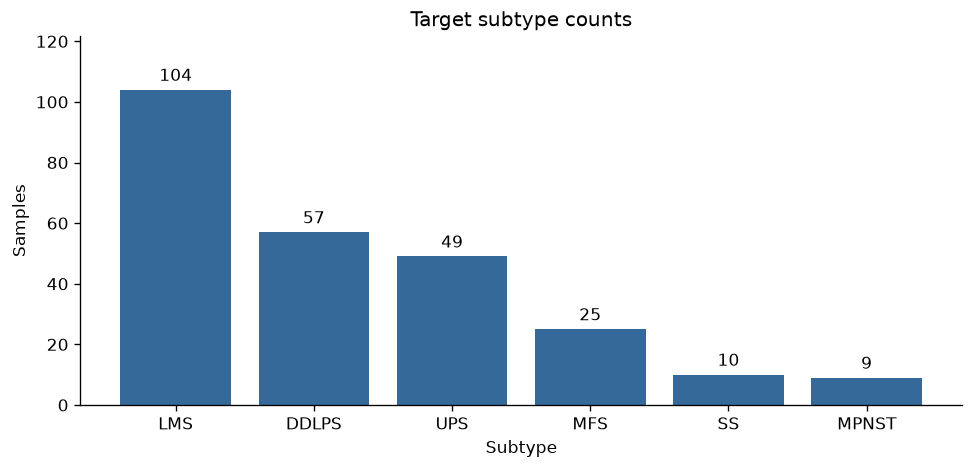

In [5]:
# Show the subtypes in the order listed in our settings.
class_order = list(config["target_subtypes"].values())
class_counts = y.value_counts().reindex(class_order)
class_table = class_counts.rename("Samples").to_frame()
class_table["Share percent"] = (100 * class_counts / len(y)).round(2)
display(class_table.rename_axis("Subtype"))
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Largest-to-smallest class ratio: {imbalance_ratio:.2f}:1")

fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
bars = ax.bar(class_order, class_counts, color="#34699A")
ax.bar_label(bars, padding=3)
ax.set(title="Target subtype counts", xlabel="Subtype", ylabel="Samples")
ax.set_ylim(0, class_counts.max() * 1.17)
plt.show()


LMS has **104 samples**, while MPNST has only **nine**. The largest class is about 11.6 times the smallest.

We must check performance for each subtype. One overall accuracy score could hide poor predictions for rare classes. Our test design also needs to account for their small sample counts.


## 6 Check the expression values

Look for missing, infinite, or negative values. Count zeros and check how large the measurements are. A zero is a recorded measurement, not a missing entry.

The **median** is the middle value. The **99th percentile** is the value at or below which 99% of measurements fall.


In [6]:
values = X.to_numpy(dtype=float)
quality = pd.Series({"Missing values": int(np.isnan(values).sum()),
                     "Infinite values": int(np.isinf(values).sum()),
                     "Negative values": int((values < 0).sum()),
                     "Zero values": int((values == 0).sum()),
                     "Zero share percent": float(100 * (values == 0).mean())}, name="Value")
display(quality.to_frame())
if not np.isfinite(values).all() or (values < 0).any():
    raise ValueError("Resolve nonfinite or negative measurements before these EDA plots.")

# Summarize the range using all values, without changing X.
probabilities = [0, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
expression_quantiles = pd.Series(np.quantile(values, probabilities),
                                index=["Minimum", "25%", "Median", "75%", "95%", "99%", "Maximum"],
                                name="RSEM expression")
display(expression_quantiles.to_frame())


,Value
Missing values,0.000000
Infinite values,0.000000
Negative values,0.000000
Zero values,822265.000000
Zero share percent,15.767687


,RSEM expression
Minimum,0.000000e+00
25%,3.460200e+00
Median,1.776875e+02
75%,8.086323e+02
95%,3.531965e+03
99%,1.188163e+04
Maximum,3.451446e+06


There are **no missing, infinite, or negative values**. About **15.77%** of measurements are zero.

The median is about **178**, but the maximum exceeds **3.45 million**. The values cover a very wide range. We need a clearer way to plot them; a large value alone is not a reason to delete it.


## 7 Plot the expression values

The left chart shows the original values, leaving out the highest 1% to make the rest easier to see. The right chart includes all values on a **log scale**, which compresses large numbers.

We use `log2(1 + expression)`: adding one allows us to include zeros. Only the display changes; the dataset stays the same.


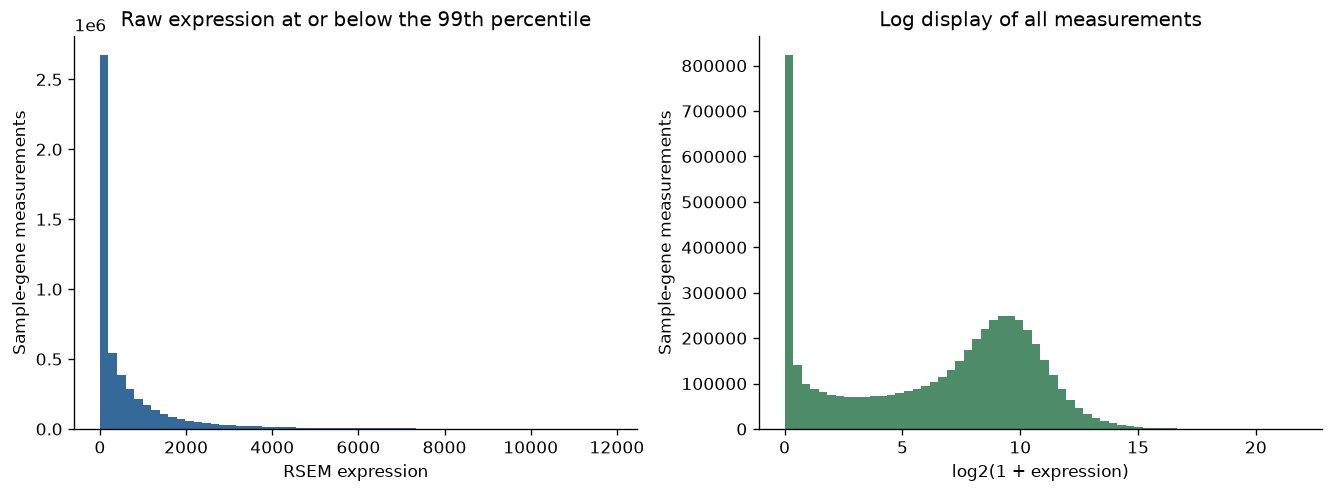

In [7]:
flat_values = values.ravel()
upper_display_limit = float(np.quantile(flat_values, 0.99))

# Create log values for plotting only; keep X unchanged.
log_values = np.log2(1 + values)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].hist(flat_values[flat_values <= upper_display_limit], bins=60, color="#34699A")
axes[0].set(title="Raw expression at or below the 99th percentile",
            xlabel="RSEM expression", ylabel="Sample-gene measurements")
axes[1].hist(log_values.ravel(), bins=60, color="#4E8B68")
axes[1].set(title="Log display of all measurements",
            xlabel="log2(1 + expression)", ylabel="Sample-gene measurements")
plt.show()


Most values are small, with a long tail of larger values. The log chart makes the range easier to see.

A log transformation may help later modeling, but these charts do not tell us whether it improves predictions. We have not applied it to the saved dataset.


## 8 Compare samples

For each sample, calculate its percentage of zeros, middle expression value, and total expression. Plot these summaries to spot samples worth reviewing.

The total is a sum of expression measurements, not a count of sequencing reads.


,zero_percent,median_expression,expression_sum
count,254.000,254.000,2.540000e+02
mean,15.768,177.972,2.147604e+07
std,2.064,23.374,2.409364e+06
min,10.345,105.278,1.719920e+07
25%,14.489,163.982,1.983197e+07
50%,15.671,178.003,2.101129e+07
75%,17.066,192.267,2.257908e+07
max,22.878,252.885,3.156073e+07


,Sample ID,Patient ID,subtype,zero_percent,median_expression,expression_sum
26,TCGA-DX-A1L4-01,TCGA-DX-A1L4,DDLPS,17.203254,174.7563,3.156073e+07
117,TCGA-DX-AB2L-01,TCGA-DX-AB2L,MFS,17.062004,180.7055,3.013703e+07
205,TCGA-QQ-A5V2-01,TCGA-QQ-A5V2,UPS,19.063855,138.4929,2.931606e+07
33,TCGA-DX-A240-01,TCGA-DX-A240,DDLPS,15.985583,184.0727,2.917892e+07
238,TCGA-X6-A7W8-01,TCGA-X6-A7W8,MFS,10.666797,152.9042,2.907169e+07


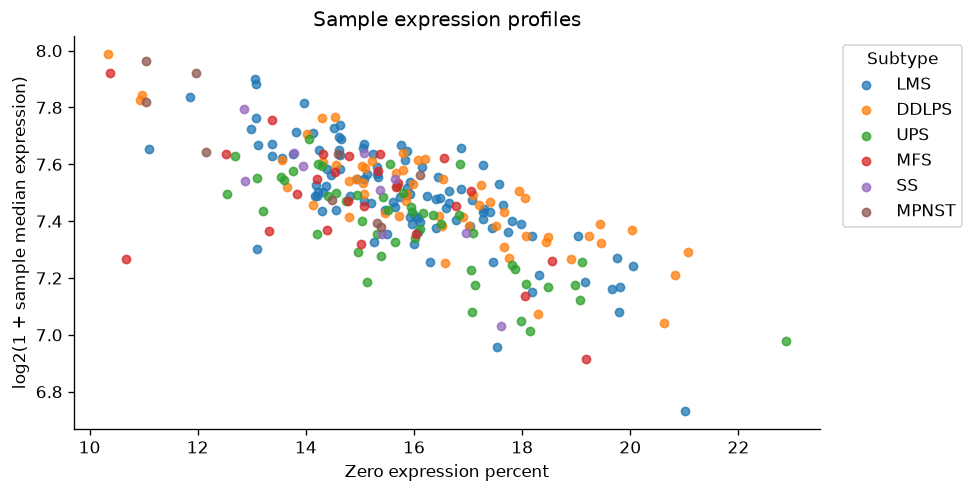

In [8]:
# Keep sample IDs and subtype labels beside these summaries.
sample_summary = dataset[["Sample ID", "Patient ID", "subtype"]].copy()
sample_summary["zero_percent"] = 100 * (values == 0).mean(axis=1)
sample_summary["median_expression"] = np.median(values, axis=1)
sample_summary["expression_sum"] = values.sum(axis=1)
display(sample_summary[["zero_percent", "median_expression", "expression_sum"]].describe().round(3))
display(sample_summary.sort_values("expression_sum", ascending=False).head(5))

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for subtype in class_order:
    rows = sample_summary[sample_summary["subtype"] == subtype]
    ax.scatter(rows["zero_percent"], np.log2(1 + rows["median_expression"]),
               label=subtype, s=24, alpha=0.75)
ax.set(title="Sample expression profiles", xlabel="Zero expression percent",
       ylabel="log2(1 + sample median expression)")
ax.legend(title="Subtype", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()


Samples have roughly **10.35% to 22.88% zero values**. Their middle expression values also vary. The table lists the five largest expression totals for closer review.

Variation does not prove a sample is faulty. We keep every sample and do not remove anything based on this plot.


## 9 Find genes with little or no variation

A **constant gene** has the same value in every sample. It cannot help distinguish these samples. Count these genes and check how often other genes have values above zero.

The table compares possible cutoffs, but does not choose or apply one.


,Count
Total gene records,20531
All-zero gene records,310
Constant gene records,310
Nonzero constant records,0


,At least this share of samples positive,Gene records
0,10%,19164
1,25%,18399
2,50%,17389
3,75%,16296
4,90%,15297
5,100%,12787


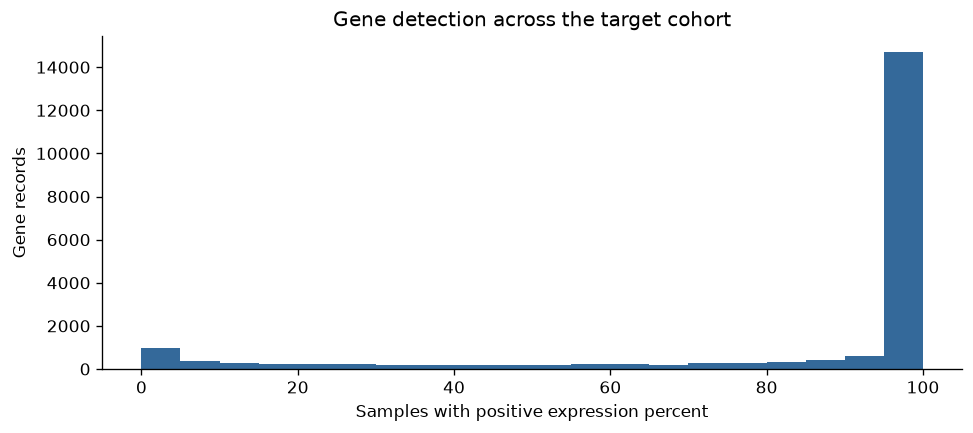

In [9]:
gene_summary = gene_map.copy()
gene_summary["positive_samples"] = (values > 0).sum(axis=0)
gene_summary["positive_fraction"] = (values > 0).mean(axis=0)
gene_summary["constant"] = X.nunique(dropna=False).to_numpy() <= 1
gene_summary["all_zero"] = (values == 0).all(axis=0)
display(pd.Series({"Total gene records": len(gene_summary),
                   "All-zero gene records": int(gene_summary["all_zero"].sum()),
                   "Constant gene records": int(gene_summary["constant"].sum()),
                   "Nonzero constant records": int((gene_summary["constant"] & ~gene_summary["all_zero"]).sum())},
                  name="Count").to_frame())

# Compare possible cutoffs without removing genes from X.
detection_table = pd.DataFrame([
    {"At least this share of samples positive": f"{threshold:.0%}",
     "Gene records": int((gene_summary["positive_fraction"] >= threshold).sum())}
    for threshold in [0.10, 0.25, 0.50, 0.75, 0.90, 1.00]
])
display(detection_table)
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.hist(100 * gene_summary["positive_fraction"], bins=20, color="#34699A")
ax.set(title="Gene detection across the target cohort", xlabel="Samples with positive expression percent",
       ylabel="Gene records")
plt.show()


**310 gene records are zero in every sample.** These are also the only constant records.

We keep all genes for now. Later, filtering rules must be learned from training samples only, rather than using test samples to decide which genes to keep.


## 10 Find repeated gene names and IDs

Each gene record has a **symbol** (its name) and an **Entrez ID** (a database identifier). Some names or IDs appear more than once.

Count the repeated identifiers and show examples. Two appearances mean one extra occurrence; the table reports both counts.


In [10]:
duplicate_rows = []
for identifier in ["Hugo_Symbol", "Entrez_Gene_Id"]:
    present = gene_map[identifier].dropna()
    sizes = present.value_counts()
    duplicated_sizes = sizes[sizes > 1]
    duplicate_rows.append({"Identifier": identifier,
                           "Missing records": int(gene_map[identifier].isna().sum()),
                           "Duplicated identifiers": len(duplicated_sizes),
                           "Rows involved": int(duplicated_sizes.sum()),
                           "Extra occurrences": int((duplicated_sizes - 1).sum())})
display(pd.DataFrame(duplicate_rows))

# The original row number keeps each gene column name unique.
identifier_duplicates = gene_map[
    (gene_map["Hugo_Symbol"].notna() & gene_map["Hugo_Symbol"].duplicated(keep=False)) |
    (gene_map["Entrez_Gene_Id"].notna() & gene_map["Entrez_Gene_Id"].duplicated(keep=False))
]
display(identifier_duplicates.head(15))
print(f"Showing 15 of {len(identifier_duplicates)} records with a repeated identifier.")
assert gene_map["feature_column"].is_unique


,Identifier,Missing records,Duplicated identifiers,Rows involved,Extra occurrences
0,Hugo_Symbol,1,17,34,17
1,Entrez_Gene_Id,0,24,50,26


,feature_column,source_gene_row,Hugo_Symbol,Entrez_Gene_Id
1,gene__UBE2Q2P3__100133144__row2,2,UBE2Q2P3,100133144
2,gene__UBE2Q2P3__100134869__row3,3,UBE2Q2P3,100134869
495,gene__PALM2AKAP2__445815__row496,496,PALM2AKAP2,445815
939,gene__SH3D20__201176__row940,940,SH3D20,201176
948,gene__ARHGAP42__143872__row949,949,ARHGAP42,143872
1642,gene__BTBD8__284697__row1643,1643,BTBD8,284697
1683,gene__NEBL__10529__row1684,1684,NEBL,10529
1694,gene__LCOR__84458__row1695,1695,LCOR,84458
1695,gene__CC2D2B__387707__row1696,1696,CC2D2B,387707
1719,gene__CCDC7__79741__row1720,1720,CCDC7,79741


Showing 15 of 70 records with a repeated identifier.


There are **17 repeated symbols** and **24 repeated Entrez IDs**, plus one missing symbol. These produce 17 and 26 extra occurrences respectively.

Each record still has a unique column name. Matching names do not necessarily mean matching measurements. The next section checks that. The preview shows 15 of 70 affected records.


## 11 Check whether repeated identifiers have the same values

Compare the measurements for records that share a name or ID. Check both our 254 selected samples and all 263 original expression samples.

This tells us whether the records are exact numerical copies.


In [11]:
# Load all original samples to check for copied measurements.
source_frame = pd.read_csv(config["expression_file"], sep="\t")
source_matrix = source_frame.iloc[:, 2:].to_numpy(dtype=float).T
source_positions = dict(zip(gene_map["feature_column"], gene_map["source_gene_row"] - 1))
pair_records = []
for identifier in ["Hugo_Symbol", "Entrez_Gene_Id"]:
    present_rows = gene_map.dropna(subset=[identifier])
    for value, group in present_rows.groupby(identifier, sort=True):
        if len(group) < 2:
            continue
        for left, right in combinations(group["feature_column"], 2):
            full_left = source_matrix[:, source_positions[left]]
            full_right = source_matrix[:, source_positions[right]]
            pair_records.append({"Identifier type": identifier, "Identifier": value,
                                 "Left feature": left, "Right feature": right,
                                 "Equal in target cohort": bool(np.array_equal(X[left], X[right], equal_nan=True)),
                                 "Equal in all source samples": bool(np.array_equal(full_left, full_right, equal_nan=True))})
duplicate_pairs = pd.DataFrame(pair_records)
display(duplicate_pairs.groupby("Identifier type").agg(
    compared_pairs=("Identifier", "size"),
    equal_in_target=("Equal in target cohort", "sum"),
    equal_in_full_source=("Equal in all source samples", "sum")))
display(duplicate_pairs.head(12))
print("Full source rows, including annotation:", int(source_frame.duplicated().sum()))
del source_frame, source_matrix


,compared_pairs,equal_in_target,equal_in_full_source
Identifier type,,,
Entrez_Gene_Id,28,0,0
Hugo_Symbol,17,0,0


,Identifier type,Identifier,Left feature,Right feature,Equal in target cohort,Equal in all source samples
0,Hugo_Symbol,C1orf84,gene__C1orf84__149469__row2258,gene__C1orf84__23334__row8940,False,False
1,Hugo_Symbol,C5orf23,gene__C5orf23__79614__row2551,gene__C5orf23__4883__row12055,False,False
2,Hugo_Symbol,CC2D2B,gene__CC2D2B__387707__row1696,gene__CC2D2B__387707__row3056,False,False
3,Hugo_Symbol,CCDC7,gene__CCDC7__79741__row1720,gene__CCDC7__221016__row3185,False,False
4,Hugo_Symbol,CYorf15B,gene__CYorf15B__246126__row4618,gene__CYorf15B__84663__row4619,False,False
5,Hugo_Symbol,ELMOD1,gene__ELMOD1__55531__row5534,gene__ELMOD1__55531__row10082,False,False
6,Hugo_Symbol,LINC00875,gene__LINC00875__388685__row6506,gene__LINC00875__100286793__row9775,False,False
7,Hugo_Symbol,NBPF16,gene__NBPF16__284565__row11581,gene__NBPF16__728936__row11582,False,False
8,Hugo_Symbol,NCRNA00185,gene__NCRNA00185__55410__row11676,gene__NCRNA00185__83869__row18906,False,False
9,Hugo_Symbol,NEBL,gene__NEBL__10529__row1684,gene__NEBL__10529__row11751,False,False


Full source rows, including annotation: 0


**None of the compared pairs has identical measurements.** We also found no completely duplicated original rows. We should not delete these records just because their names or IDs match.

The preview shows 12 comparisons. Some pairs are checked under both name and ID, so adding the two counts would count some pairs twice. We leave all records separate until we agree on how to handle their gene identifiers.


## 12 Compare the two subtype descriptions

Our labels come from `Cancer Type Detailed`. Another field contains **histology** descriptions: descriptions of the tumor tissue.

Group familiar histology descriptions under the same six subtype names, then compare the fields. This is a consistency check, not a new diagnosis.


In [12]:
# List the descriptions we group together so others can check our choices.
histology_audit_map = {
    "Leiomyosarcoma (LMS)": "LMS",
    "Dedifferentiated liposarcoma": "DDLPS",
    "Pleomorphic 'MFH' / Undifferentiated pleomorphic sarcoma": "UPS",
    "Undifferentiated Pleomorphic Sarcoma (UPS)": "UPS",
    "Giant cell 'MFH' / Undifferentiated pleomorphic sarcoma with giant cells": "UPS",
    "Myxofibrosarcoma": "MFS",
    "Malignant Peripheral Nerve Sheath Tumors (MPNST)": "MPNST",
    "Synovial Sarcoma - Monophasic": "SS",
    "Synovial Sarcoma - Biphasic": "SS",
    "Sarcoma; synovial; poorly differentiated": "SS",
    "Desmoid Tumor": "Desmoid",
}
label_review = full_clinical.copy()
label_review["configured_target"] = label_review["Cancer Type Detailed"].map(config["target_subtypes"])
label_review["histology_audit_group"] = label_review["Neoplasm Histologic Type Name"].map(histology_audit_map)
label_review["included"] = label_review["configured_target"].notna()
included_labels = label_review[label_review["included"]]
disagreements = included_labels[
    included_labels["configured_target"] != included_labels["histology_audit_group"]]

# Use short subtype names to make the comparison table readable.
review_rows = label_review["configured_target"].fillna(label_review["Cancer Type Detailed"])
display(pd.crosstab(review_rows, label_review["histology_audit_group"].fillna("Unmapped"),
                    rownames=["Configured class or excluded clinical label"], colnames=["Histology audit group"]))
print(f"Included samples with nonmatching or unmapped histology groups: {len(disagreements)}")
excluded_target_histology = label_review[
    ~label_review["included"] & label_review["histology_audit_group"].isin(class_order)]
display(excluded_target_histology[["Sample ID", "Cancer Type Detailed",
                                  "Neoplasm Histologic Type Name", "histology_audit_group"]])


Histology audit group,DDLPS,Desmoid,LMS,MFS,MPNST,SS,UPS
Configured class or excluded clinical label,,,,,,,
DDLPS,57,0,0,0,0,0,0
Desmoid/Aggressive Fibromatosis,0,2,0,0,0,0,0
LMS,0,0,104,0,0,0,0
MFS,0,0,0,25,0,0,0
MPNST,0,0,0,0,9,0,0
Pleomorphic Liposarcoma,0,0,0,0,0,0,2
SS,0,0,0,0,0,10,0
Soft Tissue,0,0,2,0,1,0,1
Soft Tissue Sarcoma,1,0,0,0,0,0,0


Included samples with nonmatching or unmapped histology groups: 0


,Sample ID,Cancer Type Detailed,Neoplasm Histologic Type Name,histology_audit_group
0,TCGA-3B-A9HI-01,Soft Tissue Sarcoma,Dedifferentiated liposarcoma,DDLPS
173,TCGA-K1-A3PN-02,Soft Tissue,Leiomyosarcoma (LMS),LMS
177,TCGA-K1-A42X-02,Soft Tissue,Leiomyosarcoma (LMS),LMS
224,TCGA-SI-A71O-06,Soft Tissue,Malignant Peripheral Nerve Sheath Tumors (MPNST),MPNST
230,TCGA-UE-A6QT-01,Pleomorphic Liposarcoma,Undifferentiated Pleomorphic Sarcoma (UPS),UPS
231,TCGA-UE-A6QU-01,Pleomorphic Liposarcoma,Undifferentiated Pleomorphic Sarcoma (UPS),UPS
234,TCGA-VT-A80J-02,Soft Tissue,Undifferentiated Pleomorphic Sarcoma (UPS),UPS


All **254 included samples agree** with the histology groups we defined.

Seven excluded samples need review: five have vague clinical labels but more specific histology descriptions; two say Pleomorphic Liposarcoma in one field and UPS in the other. The two desmoid samples remain outside our target subtypes.

We record these differences and keep the original labels and sample selection.


## 13 What we learned and what comes next

Our dataset has **254 patients and 20,531 gene records**, with no missing expression values. The notebook found issues to consider before modeling:

| Finding | Next action |
| --- | --- |
| Class sizes range from nine to 104 | Plan fair training and test groups; report results for every subtype |
| Expression values cover a wide range | Consider a log transformation and scaling |
| 310 gene records are always zero | Remove constant records using a rule fitted on training data |
| Repeated gene identifiers have different measurements | Review how to represent them before merging or removing records |
| Some excluded samples have conflicting or vague labels | Document the label choice and review those cases with the team |

Next, define how we will evaluate models and build a Logistic Regression baseline.

**Keep test data out of preprocessing decisions.** Learn filtering, scaling, and gene-selection rules from training samples, then apply the same rules to test samples. Otherwise, reported performance can look better than it really is.

This notebook describes the data. It does not yet tell us which genes predict subtypes, how accurate a model will be, or whether it will work on another dataset. No data files or labels were changed.
